# Лабораторная работа №3, вариант 4

## Метод

Метод спектрального угла сравнивает направление RGB-вектора пикселя со средними цветовыми векторами классов. Пиксель относится к классу с наименьшим углом: важнее соотношение цветовых каналов, чем общая яркость. Номер класса записывается в альфа-канал.

$$j_c = \operatorname*{arg\,max}_j \frac{p^T avg_j}{\lVert avg_j \rVert}$$

Здесь $p$ — RGB-вектор пикселя, $avg_j$ — средний RGB-вектор обучающей выборки класса $j$.

## Подготовка

In [1]:
import csv
import io
import json
import os
import platform
import re
import shutil
import subprocess
import sys
from pathlib import Path
from html import escape
from IPython.display import HTML, display

work = Path("work").resolve()
work.mkdir(exist_ok=True)
os.environ["TMPDIR"] = str(work)
results = Path("report/results")
files = ["benchmark-32.csv", "benchmark-1024.csv", "benchmark-10000.csv"]
if not all((results / name).is_file() for name in files):
    subprocess.run([sys.executable, "report/run_benchmarks.py"], check=True)


## Характеристики компьютера и GPU

Параметры компьютера получаем системными командами, характеристики GPU — через CUDA Runtime.

In [2]:
def run(args):
    process = subprocess.run([str(arg) for arg in args], capture_output=True, text=True, check=True)
    if "ERROR:" in process.stderr:
        raise RuntimeError(process.stderr)
    return process.stdout

def parameter_table(title, rows):
    body = "".join(f"<tr><td>{escape(name)}</td><td>{escape(value)}</td></tr>" for name, value in rows)
    display(HTML(f"<h3>{title}</h3><table><tr><th>Параметр</th><th>Значение</th></tr>{body}</table>"))

nvcc = shutil.which("nvcc") or "/usr/local/cuda-12.8/bin/nvcc"
run([nvcc, "-O2", "report/device_info.cu", "-o", work / "device_info"])

cpu = next(line.split(":", 1)[1].strip() for line in Path("/proc/cpuinfo").read_text().splitlines() if line.startswith("model name"))
ram = int(Path("/proc/meminfo").read_text().splitlines()[0].split()[1])
disks = json.loads(run(["lsblk", "-J", "-d", "-b", "-e", "7", "-o", "NAME,MODEL,SIZE,ROTA,TYPE"]))["blockdevices"]

def disk_description(rotating):
    items = [f"{'NVMe ' if disk['name'].startswith('nvme') else ''}{(disk['model'] or disk['name']).strip()}, {int(disk['size']) / 2**30:.1f} ГиБ" for disk in disks if disk["type"] == "disk" and bool(disk["rota"]) == rotating]
    return "; ".join(items) or "Не обнаружен"

version = run([nvcc, "--version"])
toolkit = re.search(r"release ([0-9.]+)", version).group(1)
compiler_cuda = re.search(r"V([0-9.]+)", version).group(1)
driver = run(["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"]).splitlines()[0]
compiler_cpu = run(["g++", "-dumpfullversion"]).strip()
computer = [
    ["CPU", f"{cpu}; {os.cpu_count()} логических потоков"],
    ["Оперативная память", f"{ram / 2**20:.2f} ГиБ ({ram:,} КиБ)".replace(",", " ")],
    ["SSD", disk_description(False)],
    ["Жёсткий диск", disk_description(True)],
    ["ОС", f"{platform.system()} {platform.release()}, {platform.machine()}, {' '.join(platform.libc_ver())}"],
    ["CUDA и драйвер", f"CUDA Toolkit {toolkit}, nvcc {compiler_cuda}; NVIDIA {driver}"],
    ["Компилятор CPU", f"g++ {compiler_cpu}; -O2, C++17"],
]
gpu = list(csv.reader(io.StringIO(run([work / "device_info"])), delimiter="\t"))
for row in gpu:
    if row[0] in ["Глобальная память", "Разделяемая память на блок", "Константная память"]:
        count = int(row[1])
        row[1] = f"{count:,} байт".replace(",", " ")
        if row[0] != "Глобальная память":
            row[1] += f" ({count // 1024} КиБ)"
parameter_table("Таблица 1. Параметры компьютера", computer)
parameter_table("Таблица 2. Характеристики GPU", gpu)


Параметр,Значение
CPU,Intel(R) Core(TM) i7-9750H CPU @ 2.60GHz; 12 логических потоков
Оперативная память,15.50 ГиБ (16 250 048 КиБ)
SSD,"NVMe HFM256GDHTNG-8310A, 238.5 ГиБ"
Жёсткий диск,"WDC WD10SPZX-24Z10, 931.5 ГиБ"
ОС,"Linux 6.8.0-138-generic, x86_64, glibc 2.35"
CUDA и драйвер,"CUDA Toolkit 12.8, nvcc 12.8.93; NVIDIA 570.211.01"
Компилятор CPU,"g++ 11.4.0; -O2, C++17"


Параметр,Значение
Модель,NVIDIA GeForce GTX 1050
Compute capability,6.1
Глобальная память,3 158 114 304 байт
Разделяемая память на блок,49 152 байт (48 КиБ)
Константная память,65 536 байт (64 КиБ)
Регистров на блок,65536
Максимум потоков на блок,1024
"Размеры блока (x, y, z)",1024 × 1024 × 64; суммарно не более 1024 потоков
"Размеры сетки (x, y, z)",2147483647 × 65535 × 65535 блоков
Мультипроцессоров,6


## Измерения

Размеры: 32×32, 1024×1024 и 10000×10000; пять классов, десять конфигураций GPU. Для CPU и каждой конфигурации GPU выполняется по 100 повторений после прогрева.

CPU измеряется через std::chrono, GPU — через CUDA events. Подготовка данных, копирование памяти и проверки исключены из времени.

In [3]:
configs = [(1, 32), (8, 64), (16, 128), (32, 128), (64, 128), (128, 256), (256, 256), (512, 512), (1024, 512), (1024, 1024)]
sizes = [32, 1024, 10000]
measurements = []
for size in sizes:
    with (results / f"benchmark-{size}.csv").open() as file:
        rows = list(csv.DictReader(file))
    assert [(int(row["blocks"]), int(row["threads"])) for row in rows] == configs
    assert all(int(row["repeats"]) == 100 and int(row["cpu_checks"]) == 100 and int(row["gpu_checks"]) == 100 and int(row["errors"]) == 0 for row in rows)
    measurements.extend(rows)
print(f"Загружено {len(measurements)} строк из сохранённых CSV.")


Загружено 30 строк из сохранённых CSV.


## Сравнение CPU и GPU

Времена приведены в миллисекундах и усреднены по 100 повторениям.

In [4]:
def show_table(headers, rows):
    head = "<tr>" + "".join(f"<th>{item}</th>" for item in headers) + "</tr>"
    body = "".join("<tr>" + "".join(f"<td>{item}</td>" for item in row) + "</tr>" for row in rows)
    display(HTML("<table>" + head + body + "</table>"))

table = []
for row in measurements:
    table.append([f"{row['width']}×{row['height']}", f"{row['blocks']} блоков × {row['threads']} потоков", row["repeats"], f"{float(row['cpu_ms']):.6f}", f"{float(row['gpu_ms']):.6f}", f"{float(row['speedup']):.2f}", row["errors"]])
show_table(["Размер", "Конфигурация GPU", "Повторений", "CPU, мс", "GPU, мс", "CPU / GPU", "Ошибок"], table)

Размер,Конфигурация GPU,Повторений,"CPU, мс","GPU, мс",CPU / GPU,Ошибок
32×32,1 блоков × 32 потоков,100,0.019385,0.034836,0.56,0
32×32,8 блоков × 64 потоков,100,0.019385,0.009431,2.06,0
32×32,16 блоков × 128 потоков,100,0.019385,0.011080,1.75,0
32×32,32 блоков × 128 потоков,100,0.019385,0.010220,1.90,0
32×32,64 блоков × 128 потоков,100,0.019385,0.010803,1.79,0
32×32,128 блоков × 256 потоков,100,0.019385,0.009329,2.08,0
32×32,256 блоков × 256 потоков,100,0.019385,0.010598,1.83,0
32×32,512 блоков × 512 потоков,100,0.019385,0.014377,1.35,0
32×32,1024 блоков × 512 потоков,100,0.019385,0.018135,1.07,0
32×32,1024 блоков × 1024 потоков,100,0.019385,0.033229,0.58,0


## Лучшие конфигурации GPU

Для каждого размера выбираем минимальное среднее время GPU среди всех проверенных конфигураций.

In [5]:
best_rows = []
for size in sizes:
    rows = [row for row in measurements if int(row["width"]) == size]
    best = min(rows, key=lambda row: float(row["gpu_ms"]))
    best_rows.append([f"{size}×{size}", f"{best['blocks']} блоков × {best['threads']} потоков", f"{float(best['cpu_ms']):.6f}", f"{float(best['gpu_ms']):.6f}", f"{float(best['speedup']):.2f}"])
show_table(["Размер", f"Лучшая из {len(configs)} конфигураций", "CPU, мс", "GPU, мс", "Ускорение"], best_rows)

Размер,Лучшая из 10 конфигураций,"CPU, мс","GPU, мс",Ускорение
32×32,128 блоков × 256 потоков,0.019385,0.009329,2.08
1024×1024,1024 блоков × 512 потоков,8.544854,0.589302,14.50
10000×10000,1024 блоков × 512 потоков,681.855784,55.409533,12.31


## Примеры «до / после»

Слева — исходное изображение, справа — карта классов.

### Изменение яркости

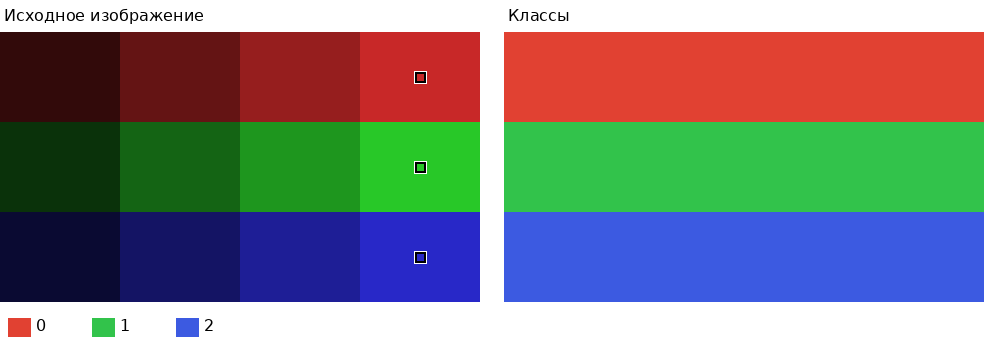

### Геометрические фигуры

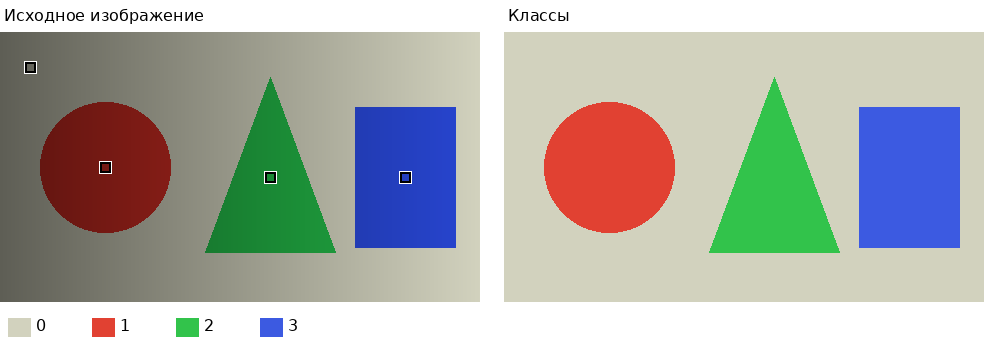

### Изображение с шумом

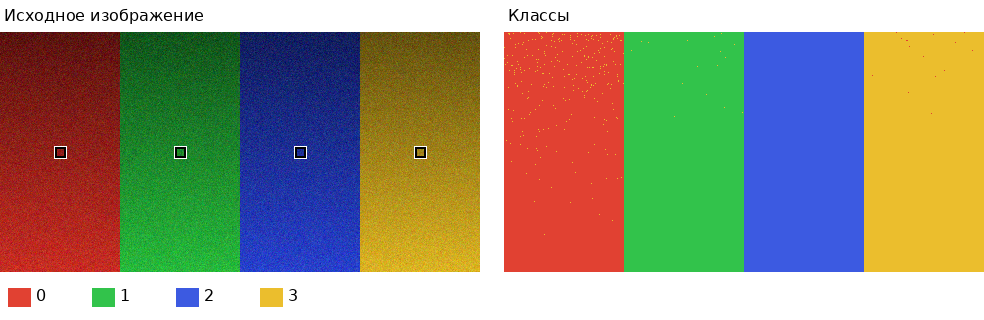

### Пример 04.data

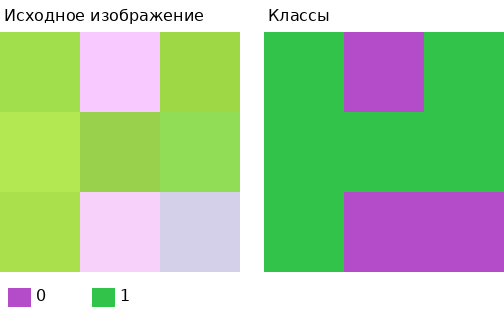

### Пример 09.data

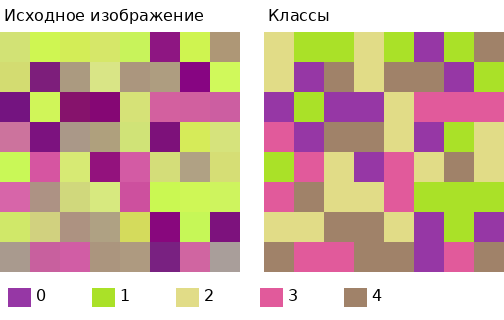